In [12]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from src.tools.data_loader import get_dataloader, get_dataset_info

In [13]:
# Choose dataset: 'mnist', 'fashion_mnist', or 'cifar10'
DATASET_NAME = 'mnist'
BATCH_SIZE = 64
DATA_DIR = './data'
MAX_SAMPLES = 10000  # Limite à 1000 images pour aller plus vite (None = pas de limite)

In [14]:
# Get dataset info
info = get_dataset_info(DATASET_NAME)
print(f"Dataset: {info['name']}")
print(f"Description: {info['description']}")
print(f"Number of classes: {info['num_classes']}")
print(f"Image shape: {info['image_shape']}")
print(f"Training samples: {info['num_train']}")
print(f"Test samples: {info['num_test']}")
print(f"Grayscale: {info['grayscale']}")

Dataset: MNIST
Description: Handwritten digits (0-9)
Number of classes: 10
Image shape: (1, 28, 28)
Training samples: 60000
Test samples: 10000
Grayscale: True


In [15]:
# Load dataloaders
train_loader, num_classes, image_shape = get_dataloader(
    dataset_name=DATASET_NAME,
    data_dir=DATA_DIR,
    batch_size=BATCH_SIZE,
    train=True,
    shuffle=True,
    max_samples=MAX_SAMPLES
)

test_loader, _, _ = get_dataloader(
    dataset_name=DATASET_NAME,
    data_dir=DATA_DIR,
    batch_size=BATCH_SIZE,
    train=False,
    shuffle=False,
    max_samples=MAX_SAMPLES
)

print(f"\nTrain batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")
if MAX_SAMPLES:
    print(f"⚡ Limited to {MAX_SAMPLES} samples per dataset")


Train batches: 157
Test batches: 157
⚡ Limited to 10000 samples per dataset


In [16]:
# Le dataloader existant est déjà prêt pour Diffusion-GAN !
print("✓ Dataloader MNIST disponible")
print(f"  - Batch size: {BATCH_SIZE}")
print(f"  - Nombre de batches: {len(train_loader)}")
print(f"  - Images normalisées dans [-1, 1]: ✓")
print(f"  - Shuffle activé: ✓")

# Dans la boucle d'entraînement, on utilisera:
print("\n📦 Structure d'un batch d'entraînement:")
x_batch, _ = next(iter(train_loader))  # On ignore les labels pour le GAN
print(f"  - Images x: {x_batch.shape}")
print(f"  - On générera z ~ N(0,I) de dimension [batch_size, latent_dim]")
print(f"  - On échantillonnera t ~ Uniform(1, T)")
print(f"  - On diffusera x et G(z) au timestep t")

✓ Dataloader MNIST disponible
  - Batch size: 64
  - Nombre de batches: 157
  - Images normalisées dans [-1, 1]: ✓
  - Shuffle activé: ✓

📦 Structure d'un batch d'entraînement:


  - Images x: torch.Size([64, 1, 28, 28])
  - On générera z ~ N(0,I) de dimension [batch_size, latent_dim]
  - On échantillonnera t ~ Uniform(1, T)
  - On diffusera x et G(z) au timestep t


In [17]:
import importlib
import sys

# Force reload des modules
if 'src.models.SNGAN_disc' in sys.modules:
    del sys.modules['src.models.SNGAN_disc']
if 'src.models.SNGAN_gen' in sys.modules:
    del sys.modules['src.models.SNGAN_gen']
if 'src.models.gan_factory' in sys.modules:
    del sys.modules['src.models.gan_factory']

import src.models.gan_factory as gan_factory

generator, discriminator = gan_factory.create_gan_models(
    variant='sngan',
    use_diffusion=False,
    image_channels=1 if info['grayscale'] else 3,
    z_dim=128,
    time_embedding_dim=128,
    gen_channels=[256, 128, 64],
    disc_channels=[64, 128, 256],
)

In [18]:
import tqdm 
from torch.utils.tensorboard import SummaryWriter
from datetime import datetime
import os

# TensorBoard setup
log_dir = './runs'
os.makedirs(log_dir, exist_ok=True)
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
run_name = f'diffusion_gan_{timestamp}'
writer = SummaryWriter(os.path.join(log_dir, run_name))

print(f"📊 TensorBoard: tensorboard --logdir={log_dir}")
print(f"📁 Run: {run_name}\n")

# Vérifier CUDA
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA version: {torch.version.cuda}")

T_max = 0
step = 0
C = 1
target_d = 0.6
num_epochs = 10
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}\n')

# Move models to device
generator = generator.to(device)
discriminator = discriminator.to(device)

# Criterion
criterion = torch.nn.BCEWithLogitsLoss()

optimizer_g = torch.optim.Adam(generator.parameters(), lr=0.0001, betas=(0.0, 0.99))
optimizer_d = torch.optim.Adam(discriminator.parameters(), lr=0.0001, betas=(0.0, 0.99))

global_step = 0

for epoch in range(num_epochs):
    pbar = tqdm.tqdm(train_loader, desc=f'Epoch [{epoch+1:3d}/{num_epochs}]', 
                     unit='batch', ncols=120, leave=True)
    
    epoch_d_loss = 0
    epoch_g_loss = 0
    batch_count = 0
    
    for images, _ in pbar:
        images = images.to(device)
        batch_size = images.size(0)

        # Train discriminator
        optimizer_d.zero_grad()
        optimizer_g.zero_grad()
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        real_outputs = discriminator(images)
        d_loss_real = criterion(real_outputs, real_labels)

        noise = torch.randn(batch_size, 128).to(device)
        fake_images = generator(noise)

        fake_outputs = discriminator(fake_images.detach())
        d_loss_fake = criterion(fake_outputs, fake_labels)

        d_loss = d_loss_real + d_loss_fake

        d_loss.backward()
        optimizer_d.step()

        # Train generator
        optimizer_d.zero_grad()
        optimizer_g.zero_grad()
        fake_outputs = discriminator(fake_images)
        g_loss = criterion(fake_outputs, real_labels)
        g_loss.backward()
        optimizer_g.step()

        # Accumulate losses
        d_loss_val = d_loss.item()
        g_loss_val = g_loss.item()
        epoch_d_loss += d_loss_val
        epoch_g_loss += g_loss_val
        batch_count += 1
        
        # Write to TensorBoard
        writer.add_scalar('Loss/D', d_loss_val, global_step)
        writer.add_scalar('Loss/G', g_loss_val, global_step)
        
        global_step += 1

        # Update progress bar with losses
        avg_d = epoch_d_loss / batch_count
        avg_g = epoch_g_loss / batch_count
        pbar.set_postfix({'D_loss': f'{avg_d:.4f}', 'G_loss': f'{avg_g:.4f}'})

# Save models
torch.save(generator.state_dict(), f'./models/generator_{run_name}.pt')
torch.save(discriminator.state_dict(), f'./models/discriminator_{run_name}.pt')
print(f"\n✅ Models saved to ./models/")
print(f"📊 View results: tensorboard --logdir={log_dir}")

writer.close()

📊 TensorBoard: tensorboard --logdir=./runs
📁 Run: diffusion_gan_20260108_232017

CUDA available: True
CUDA device: NVIDIA GeForce RTX 5070
CUDA version: 12.8
Using device: cuda



Epoch [ 10/10]: 100%|███████████████████████████████| 157/157 [00:13<00:00, 11.67batch/s, D_loss=0.0000, G_loss=17.6346]


✅ Models saved to ./models/
📊 View results: tensorboard --logdir=./runs


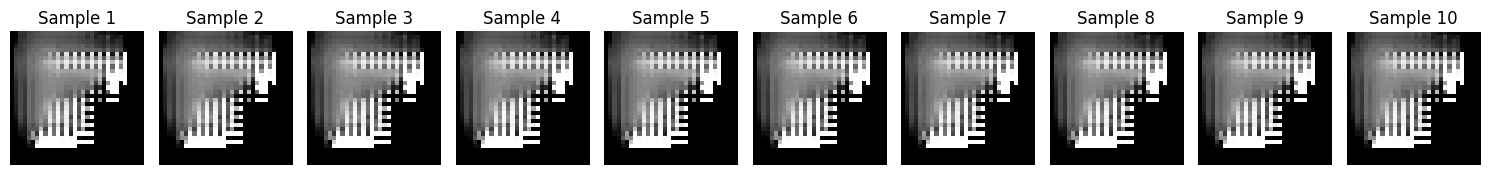

In [20]:
# Plot Generated Images

n_images = 10
noise = torch.randn(n_images, 128).to(device)  # z_dim=128, pas 100!
generated_images = generator(noise)
generated_images = generated_images.detach().cpu().numpy()

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, n_images, figsize=(15, 2))
for i in range(n_images):
    # Format: [batch, channels, height, width] -> [height, width]
    img = generated_images[i, 0]  # Take first (only) channel
    # Normalize to [0, 1] for display
    img = (img + 1) / 2
    img = np.clip(img, 0, 1)
    
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f'Sample {i+1}')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

## TensorBoard

Lance cette commande dans le terminal pour voir les losses en temps réel:
```bash
tensorboard --logdir ./runs
```

Puis ouvre http://localhost:6006 dans le navigateur.